In [238]:
import pandas as pd
import numpy as np
from sklearn.manifold import MDS
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & PATHS ---
PATH_TO_DF = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/29. polycategoriality/master_typological_matrix_all_langs.csv"
PATH_GROUPS = '/Users/madalina/Downloads/Typometrics configuration - language to group.csv'
PATH_MARKERS = '/Users/madalina/Downloads/Typometrics configuration - appearance.csv'

LANGS_TO_EXCLUDE = [
    "Central_Kurdish-Mukri", "Tswana-Popapolelo", "Azerbaijani-TueCL", "Madi-Jarawara", 
    "Kaapor-TuDeT", "Assyrian-AS", "Yupik-SLI", "Warlpiri-UFAL", "Old_Irish-DipSGG", 
    "Apurina-UFPA", "Sinhala-STB", "Komi_Permyak-UH", "Malayalam-UFAL", "Bengali-BRU", 
    "Neapolitan-RB", "Naga-Suansu", "Skolt_Sami-Giellagas", "Abaza-ATB", 
    "Macedonian-MTB", "Tagalog-Ugnayan", "Turkish"
]

LANG_TO_INCLUDE = [
    "Gheg", "Bulgarian", "Belarusian", "Russian", "Ukrainian", "Polish", "Slovak",
    "Czech", "Slovenian", "Croatian", "Serbian", "UpperSorbian", "German", "Dutch", "Afrikaans", "English",
    "Norwegian", "Swedish", "Danish", "Icelandic", "Faroese", "Romanian", "Pomak", "Breton", "Greek", "Catalan", "Spanish",
    "Portuguese", "Italian", "French", "Galician", "Maltese", "Hebrew", "Welsh", "Irish", "ScottishGaelic", "Manx", "Kurmanji",
    "Persian", "Arabic", "Javanese", "Indonesian", "Vietnamese", "Thai", "Urdu", "Hindi", "Japanese", "Xibe", "Uyghur", "Kazakh", "Turkish",
    "Buryat", "Tamil", "Basque", "Korean", "Hungarian", "NorthSami", "Finnish", "Estonian", "Lithuanian", "Latvian", "Armenian", "WesternArmenian", 
    "Erzya", "KomiZyrian", "Chinese", "Cantonese"
]

# --- 2. DATA LOADING & CLEANING ---
master_df = pd.read_csv(PATH_TO_DF, index_col=0)
master_df = master_df.drop(index=[l for l in LANGS_TO_EXCLUDE if l in master_df.index])

# --- 3. FEATURE SELECTION ---
def get_clean_features(df):
    # Initial selection based on ADJ, NOUN, VERB
    relevant_poses = ["ADJ", "NOUN", "VERB"]
    cols = []
    for col in df.columns:
        # Keep main category and arrows involving relevant POS
        if col == "ADJ" or ("->" in col and any(p in col.split("->") for p in relevant_poses)):
            cols.append(col)
    
    # Filter out noise (INTJ, X, etc.) and specific exclusions you mentioned
    noise = ["INTJ", "X", "SYM", "SCONJ", "CCONJ", "PROPN", "ADP", "AUX", "PART", "PRON", "variance"]
    clean_cols = [c for c in cols if not any(n in c.replace('->', '_') for n in noise)]
    
    # Final specific removals from your list
    exclude_specific = ["VERB->DET", "VERB->NUM", "DET->VERB", "VERB->VERB", "ADJ->ADJ", "NOUN->NOUN"]

    clean_cols = [c for c in clean_cols if c not in exclude_specific]
    
    return df[clean_cols].dropna(thresh=10)

In [239]:
pos_df = get_clean_features(master_df)

In [240]:
# --- 4. MERGE METADATA (Groups & Markers) ---
# Prepare the key to match "Akkadian_RIAO" -> "Akkadian"
metadata_df = pos_df.copy()
metadata_df['Language_Key'] = metadata_df.index.str.split('-').str[0].str.replace('_', '')

df_groups = pd.read_csv(PATH_GROUPS)
# df_markers = pd.read_csv(PATH_MARKERS)

# Merge everything into one master 'styled_df'
styled_df = metadata_df[['Language_Key']].merge(df_groups, left_on='Language_Key', right_on='Language', how='left')
# styled_df = styled_df.merge(df_markers, on='Group', how='left')
styled_df.index = pos_df.index # Keep original treebank index

In [241]:
# Filter styled_df to only include languages in LANG_TO_INCLUDE
styled_df = styled_df[styled_df['Language_Key'].isin(LANG_TO_INCLUDE)]

# Filter pos_df to match the same rows as styled_df
pos_df = pos_df.loc[styled_df.index]

In [242]:
def check_language_match(df, lang_list, lang_col='Language_Key'):
    """
    Checks if languages in dataframe match the provided list.
    
    Returns:
        dict with 'match' (bool), 'missing' (languages in list but not in df),
        'extra' (languages in df but not in list)
    """
    df_langs = set(df[lang_col].unique())
    expected_langs = set(lang_list)
    
    missing = expected_langs - df_langs
    extra = df_langs - expected_langs
    
    match = len(missing) == 0 and len(extra) == 0
    
    print(f"Perfect match: {match}")
    if missing:
        print(f"Missing from dataframe: {sorted(missing)}")
    if extra:
        print(f"Extra in dataframe: {sorted(extra)}")
    
    return {
        'match': match,
        'missing': sorted(missing),
        'extra': sorted(extra)
    }

# Usage:
check_language_match(styled_df, LANG_TO_INCLUDE)

Perfect match: False
Missing from dataframe: ['Kurmanji']


{'match': False, 'missing': ['Kurmanji'], 'extra': []}

In [243]:
# --- 5. GOWER DISTANCE CALCULATION ---
def manual_gower_matrix(df, cat_cols):
    n = df.shape[0]
    dist_matrix = np.zeros((n, n))
    num_cols = [c for c in df.columns if c not in cat_cols]
    col_ranges = df[num_cols].max() - df[num_cols].min()
    data = df.values
    col_names = list(df.columns)
    cat_indices = [col_names.index(c) for c in cat_cols]
    
    for i in range(n):
        for j in range(i + 1, n):
            sims, w = [], []
            for idx in range(df.shape[1]):
                v_i, v_j = data[i, idx], data[j, idx]
                if pd.isna(v_i) or pd.isna(v_j): continue
                
                if idx in cat_indices:
                    s = 1.0 if v_i == v_j else 0.0
                else:
                    r = col_ranges.iloc[num_cols.index(col_names[idx])]
                    s = 1.0 - (abs(v_i - v_j) / r) if r != 0 else 1.0
                sims.append(s); w.append(1.0)
            
            res = 1.0 - (sum(sims)/sum(w)) if sum(w) > 0 else 1.0
            dist_matrix[i, j] = dist_matrix[j, i] = res
    return dist_matrix

In [244]:
dist_matrix = manual_gower_matrix(pos_df, cat_cols=["ADJ"])

In [245]:
# --- 6. MDS / PCoA ---
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
coords = mds.fit_transform(dist_matrix)
styled_df['X'], styled_df['Y'] = coords[:, 0], coords[:, 1]

In [246]:
styled_df

,Language_Key,Language,Group,Genus,Column 1,Simple Group,Area,Column 2,OK,Sub-Group,...,2.15,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,X,Y
Language,,,,,,,,,,,,,,,,,,,,,
Armenian-ArmTDP,Armenian,Armenian,Indo-European,Other,Armenian,Indo-European,E,NaN,NaN,Armenian,...,"Armenian 2 94K IE, Armenian",NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.120907,-0.080396
Welsh-CCG,Welsh,Welsh,Indo-European,Celtic,NaN,Indo-European,E,NaN,NaN,Celtic,...,"Welsh 1 52K IE, Celtic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.097816,-0.131010
Gheg-GPS,Gheg,Gheg,Indo-European,Other,Albanian,Indo-European,E,NaN,NaN,Balkan,...,"Gheg 1 15K IE, Albanian",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.235693,0.000926
Indonesian-GSD,Indonesian,Indonesian,Sino-Austronesian,NaN,NaN,Sino-Austronesian,O,NaN,NaN,Austronesian,...,"Indonesian 3 169K Austronesian, Malayo-Sumbawan",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.092097,-0.003193
Ukrainian-IU,Ukrainian,Ukrainian,Indo-European,Baltoslavic,NaN,Indo-European,E,NaN,NaN,Slavic,...,"Ukrainian 2 174K IE, Slavic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.168944,-0.047071
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Scottish_Gaelic-ARCOSG,ScottishGaelic,ScottishGaelic,Indo-European,Celtic,NaN,Indo-European,E,NaN,NaN,Celtic,...,"Scottish Gaelic 1 89K IE, Celtic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.045169,-0.169550
Portuguese-GSD,Portuguese,Portuguese,Indo-European,Italic,NaN,Indo-European,E,NaN,NaN,Romance,...,"Portuguese 7 1,545K IE, Romance",NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.081276,0.205251
Arabic-PADT,Arabic,Arabic,Semitic,NaN,NaN,Afroasiatic,ME,NaN,NaN,Semitic,...,"Arabic 3 1,042K Afro-Asiatic, Semitic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.212465,0.096171


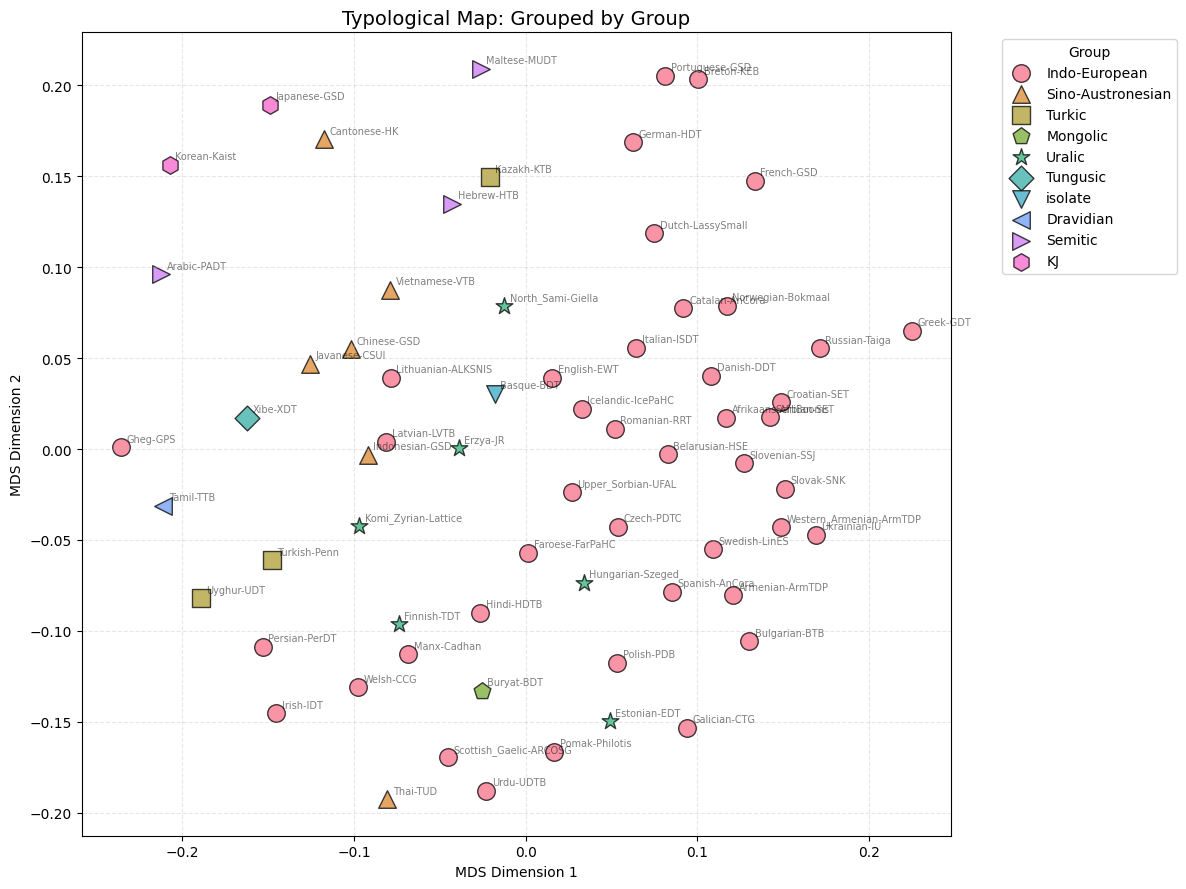

In [305]:
import seaborn as sns

def plot_typology_dynamic(metadata_df, category='Area'):
    """
    Plots the MDS coordinates colored and shaped by any column in the dataframe.
    """
    plt.figure(figsize=(12, 9))
    
    # 1. Setup Colors and Markers automatically
    unique_vals = metadata_df[category].unique()
    # Handle cases where some languages might have NaN in the category
    unique_vals = [v for v in unique_vals if pd.notna(v)]
    
    palette = sns.color_palette("husl", len(unique_vals))
    color_map = dict(zip(unique_vals, palette))
    
    # List of matplotlib markers to cycle through
    all_markers = ['o', '^', 's', 'p', '*', 'D', 'v', '<', '>', 'h']
    marker_map = {val: all_markers[i % len(all_markers)] for i, val in enumerate(unique_vals)}

    # 2. Plot each group
    for val in unique_vals:
        subset = metadata_df[metadata_df[category] == val]
        
        plt.scatter(
            subset['X'], subset['Y'], 
            label=val,
            color=color_map[val], 
            marker=marker_map[val], 
            s=160, 
            edgecolors='black', 
            alpha=0.75
        )

    # 3. Add Labels (Language Names)
    for idx, row in metadata_df.iterrows():
        plt.annotate(
            idx, 
            (row['X'], row['Y']), 
            size=7, 
            alpha=0.5, 
            xytext=(4, 4), 
            textcoords='offset points'
        )

    plt.title(f"Typological Map: Grouped by {category}", fontsize=14)
    plt.xlabel("MDS Dimension 1")
    plt.ylabel("MDS Dimension 2")
    plt.legend(title=category, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- EXAMPLES OF USE ---
# plot_typology_dynamic(styled_df, category='Morphological Type')
# plot_typology_dynamic(styled_df, category='Area')
plot_typology_dynamic(styled_df, category='Group')

In [248]:
styled_df

,Language_Key,Language,Group,Genus,Column 1,Simple Group,Area,Column 2,OK,Sub-Group,...,2.15,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,X,Y
Language,,,,,,,,,,,,,,,,,,,,,
Armenian-ArmTDP,Armenian,Armenian,Indo-European,Other,Armenian,Indo-European,E,NaN,NaN,Armenian,...,"Armenian 2 94K IE, Armenian",NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.120907,-0.080396
Welsh-CCG,Welsh,Welsh,Indo-European,Celtic,NaN,Indo-European,E,NaN,NaN,Celtic,...,"Welsh 1 52K IE, Celtic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.097816,-0.131010
Gheg-GPS,Gheg,Gheg,Indo-European,Other,Albanian,Indo-European,E,NaN,NaN,Balkan,...,"Gheg 1 15K IE, Albanian",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.235693,0.000926
Indonesian-GSD,Indonesian,Indonesian,Sino-Austronesian,NaN,NaN,Sino-Austronesian,O,NaN,NaN,Austronesian,...,"Indonesian 3 169K Austronesian, Malayo-Sumbawan",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.092097,-0.003193
Ukrainian-IU,Ukrainian,Ukrainian,Indo-European,Baltoslavic,NaN,Indo-European,E,NaN,NaN,Slavic,...,"Ukrainian 2 174K IE, Slavic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.168944,-0.047071
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Scottish_Gaelic-ARCOSG,ScottishGaelic,ScottishGaelic,Indo-European,Celtic,NaN,Indo-European,E,NaN,NaN,Celtic,...,"Scottish Gaelic 1 89K IE, Celtic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.045169,-0.169550
Portuguese-GSD,Portuguese,Portuguese,Indo-European,Italic,NaN,Indo-European,E,NaN,NaN,Romance,...,"Portuguese 7 1,545K IE, Romance",NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.081276,0.205251
Arabic-PADT,Arabic,Arabic,Semitic,NaN,NaN,Afroasiatic,ME,NaN,NaN,Semitic,...,"Arabic 3 1,042K Afro-Asiatic, Semitic",NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.212465,0.096171


13 [0.43691233 0.74797827]
51 [0.58834753 0.99449116]


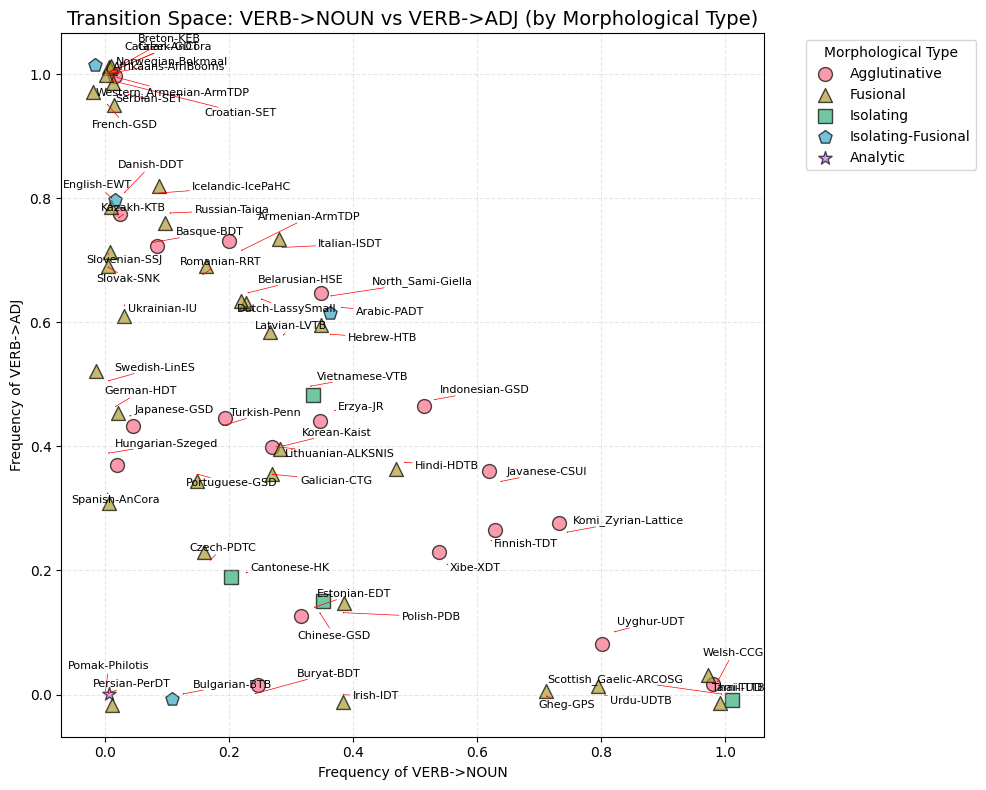

In [308]:
from adjustText import adjust_text
def plot_transition_space(data_df, metadata_df, x_col='VERB->NOUN', y_col='VERB->ADJ', category='Area'):
    """
    Plots two specific linguistic transitions against each other.
    """
    # 1. Prepare data by joining the specific columns to the metadata
    # We use the index to make sure languages match up perfectly
    plot_df = metadata_df.copy()
    plot_df[x_col] = data_df[x_col]
    plot_df[y_col] = data_df[y_col]

    plt.figure(figsize=(10, 8))
    
    # 2. Setup Auto-assigning for the chosen category
    unique_vals = [v for v in plot_df[category].unique() if pd.notna(v)]
    palette = sns.color_palette("husl", len(unique_vals))
    color_map = dict(zip(unique_vals, palette))
    all_markers = ['o', '^', 's', 'p', '*', 'D', 'v', '<', '>', 'h']
    marker_map = {val: all_markers[i % len(all_markers)] for i, val in enumerate(unique_vals)}

    # 3. Plot
    for val in unique_vals:
        subset = plot_df[plot_df[category] == val]
        jitter_x = np.random.uniform(-0.02, 0.02, size=len(subset))
        jitter_y = np.random.uniform(-0.02, 0.02, size=len(subset))
        plt.scatter(
            subset[x_col] + jitter_x, subset[y_col] + jitter_y, 
            label=val,
            color=color_map[val], 
            marker=marker_map[val], 
            s=100, edgecolors='black', alpha=0.7
        )

    # 4. Annotate
    # for idx, row in plot_df.iterrows():
    #     if pd.notna(row[x_col]) and pd.notna(row[y_col]):
    #         plt.annotate(idx, (row[x_col], row[y_col]), size=7, alpha=0.6, xytext=(4,4), textcoords='offset points')
    texts = []
    for idx, row in plot_df.iterrows():
        if pd.notna(row[x_col]) and pd.notna(row[y_col]):
            # Add the text but don't draw it yet
            texts.append(plt.text(row[x_col], row[y_col], idx, size=8))

    plt.title(f"Transition Space: {x_col} vs {y_col} (by {category})", fontsize=14)
    plt.xlabel(f"Frequency of {x_col}")
    plt.ylabel(f"Frequency of {y_col}")
    plt.legend(title=category, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    adjust_text(texts, expand=(1.2, 2), arrowprops=dict(arrowstyle='->', color='red', lw=0.5))
    plt.show()

plot_transition_space(pos_df, styled_df, x_col='VERB->NOUN', y_col='VERB->ADJ', category='Morphological Type')

In [256]:
import plotly.express as px

def plot_interactive_typology(data_df, metadata_df, x_col, y_col, category):
    # Merge data for plotly
    plot_df = metadata_df.copy()
    plot_df[x_col] = data_df[x_col]
    plot_df[y_col] = data_df[y_col]
    plot_df['Language'] = plot_df.index
    
    fig = px.scatter(plot_df, x=x_col, y=y_col, color=category,
                     hover_name='Language', 
                     title=f"Interactive {x_col} vs {y_col}")
    fig.show()

plot_interactive_typology(pos_df, styled_df, x_col='VERB->NOUN', y_col='VERB->ADJ', category='Morphological Type')

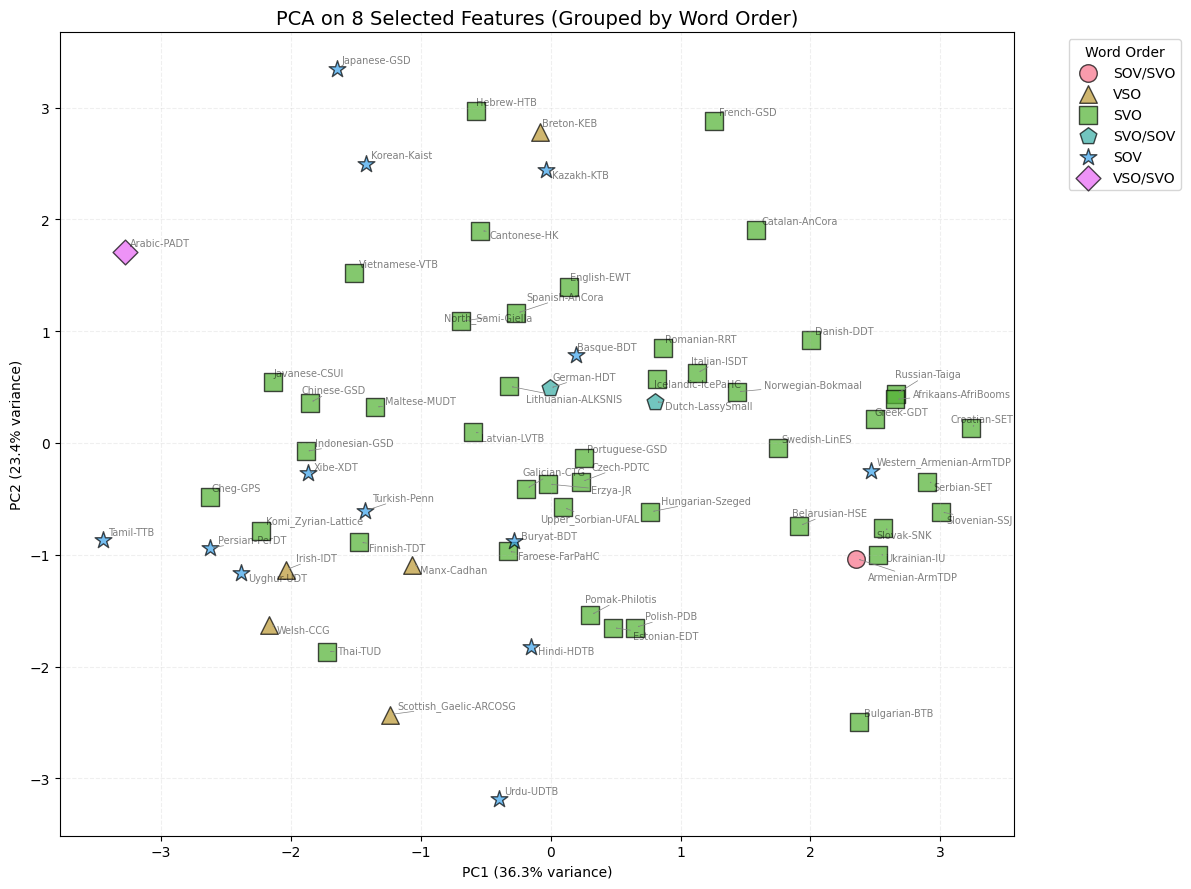

In [315]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns

def plot_custom_pca(data_df, metadata_df, target_columns, category='Area'):
    """
    Performs PCA on specific columns and plots the results.
    """
    # 1. Subset and Scale the data
    # We only take the columns you requested
    X = data_df[target_columns].fillna(0)
    # X=data_df.fillna(0)
    # X_arcsine = np.arcsin(np.sqrt(X))
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # 2. Run PCA
    pca = PCA(n_components=2)
    pca_coords = pca.fit_transform(X_scaled)
    
    # 3. Prepare Plotting Data
    plot_df = metadata_df.copy()
    plot_df['PC1'] = pca_coords[:, 0]
    plot_df['PC2'] = pca_coords[:, 1]
    
    plt.figure(figsize=(12, 9))
    
    # 4. Handle Colors/Markers (Auto-assigning for the chosen category)
    unique_vals = [v for v in plot_df[category].unique() if pd.notna(v)]
    palette = sns.color_palette("husl", len(unique_vals))
    all_markers = ['o', '^', 's', 'p', '*', 'D', 'v', '<', '>', 'h']
    
    for i, val in enumerate(unique_vals):
        subset = plot_df[plot_df[category] == val]
        plt.scatter(
            subset['PC1'], subset['PC2'], 
            label=val,
            color=palette[i], 
            marker=all_markers[i % len(all_markers)], 
            s=160, edgecolors='black', alpha=0.7
        )

    # 5. Add Language Labels (Using simple annotate)
    # for idx, row in plot_df.iterrows():
    #     plt.annotate(idx, (row['PC1'], row['PC2']), size=7, alpha=0.5, xytext=(4,4), textcoords='offset points')

    texts = []
    for idx, row in plot_df.iterrows():
        texts.append(plt.text(row['PC1'], row['PC2'], idx, size=7, alpha=0.5))

    adjust_text(
        texts,
        expand=(1.2, 1.4),
        arrowprops=dict(arrowstyle='->', color='grey', lw=0.5)
    )
    # Formatting
    var_exp = pca.explained_variance_ratio_
    plt.title(f"PCA on {len(target_columns)} Selected Features (Grouped by {category})", fontsize=14)
    # plt.title(f"PCA - (Grouped by {category})", fontsize=14)

    plt.xlabel(f"PC1 ({var_exp[0]:.1%} variance)")
    plt.ylabel(f"PC2 ({var_exp[1]:.1%} variance)")
    plt.legend(title=category, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.2)
    plt.tight_layout()
    plt.show()

# --- HOW TO RUN IT ---
my_cols = ['ADJ->DET', 'DET->ADJ', 'VERB->NOUN', 'VERB->ADJ', 'ADJ->VERB', 'ADJ->NOUN', 'NUM->NOUN', 'NUM->ADJ']
# plot_custom_pca(pos_df, styled_df, target_columns=my_cols, category='Morphological Type')
# plot_custom_pca(pos_df, styled_df, target_columns=my_cols, category='Area')
plot_custom_pca(pos_df, styled_df, target_columns=my_cols, category='Word Order')

# plot_custom_pca(pos_df, styled_df, target_columns=my_cols, category='Group')


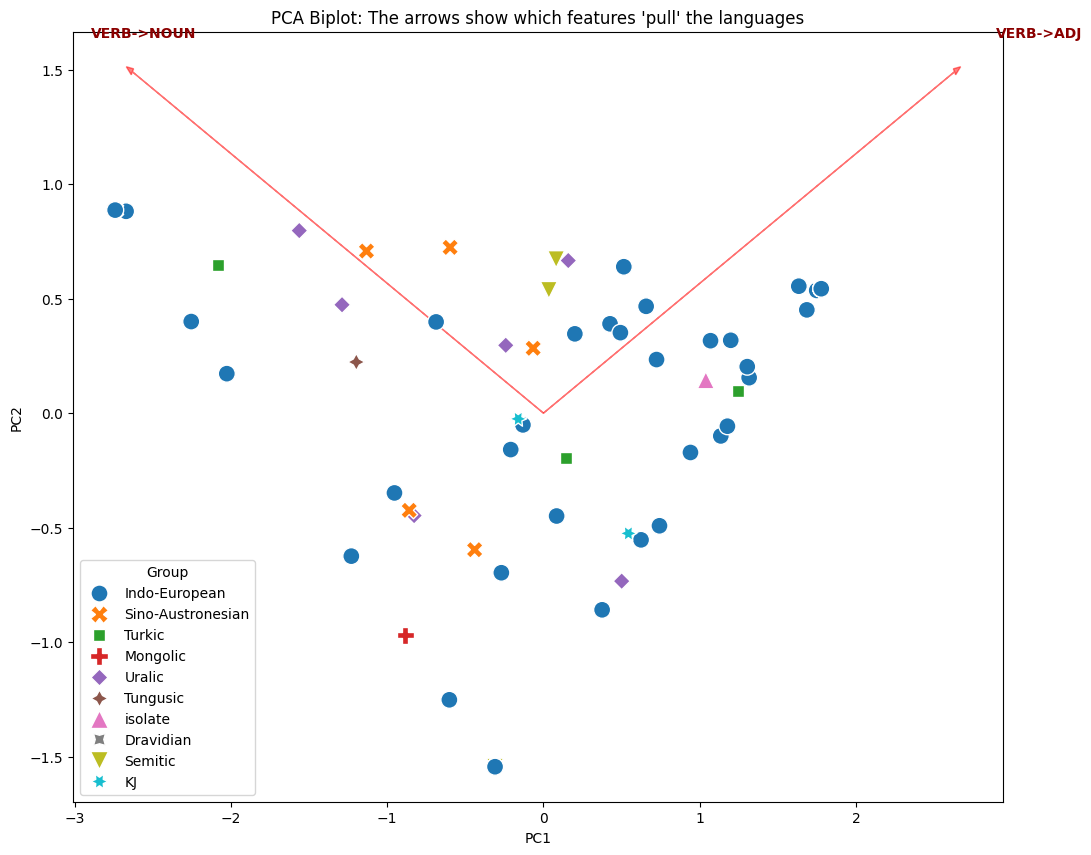

In [258]:
def plot_pca_with_arrows(data_df, metadata_df, target_cols, category='Area'):
    # 1. Prepare and Scale
    X = data_df[target_cols].fillna(0)
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2)
    coords = pca.fit_transform(X_scaled)
    
    # 2. Setup Plot
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # 3. Add the "Linguistic Compass" (Arrows)
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    for i, col_name in enumerate(target_cols):
        # We multiply by a factor (e.g., 3) to make arrows visible
        ax.arrow(0, 0, loadings[i, 0]*3, loadings[i, 1]*3, color='red', alpha=0.5, head_width=0.03)
        ax.text(loadings[i, 0]*3.3, loadings[i, 1]*3.3, col_name, color='darkred', weight='bold')

    # 4. Standard plotting logic for the languages
    plot_df = metadata_df.copy()
    plot_df['PC1'], plot_df['PC2'] = coords[:, 0], coords[:, 1]
    sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue=category, style=category, s=150, ax=ax)
    
    plt.title("PCA Biplot: The arrows show which features 'pull' the languages")
    plt.show()

plot_pca_with_arrows(pos_df, styled_df, target_cols=my_cols, category='Group')

<Axes: >

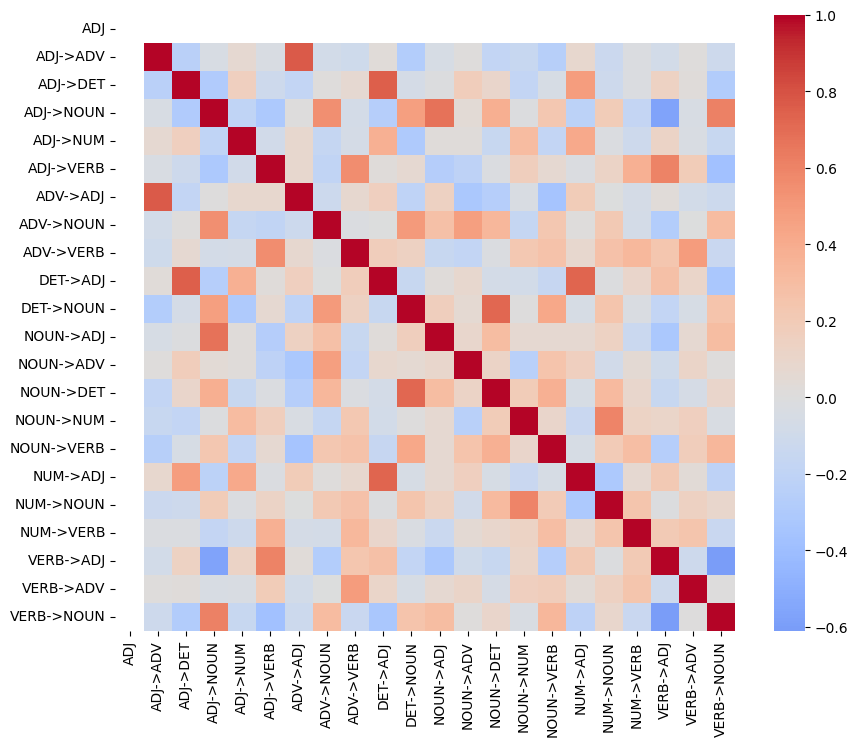

In [220]:
import seaborn as sns
plt.figure(figsize=(10,8))
sns.heatmap(pos_df.corr(method='spearman'), cmap='coolwarm', center=0)

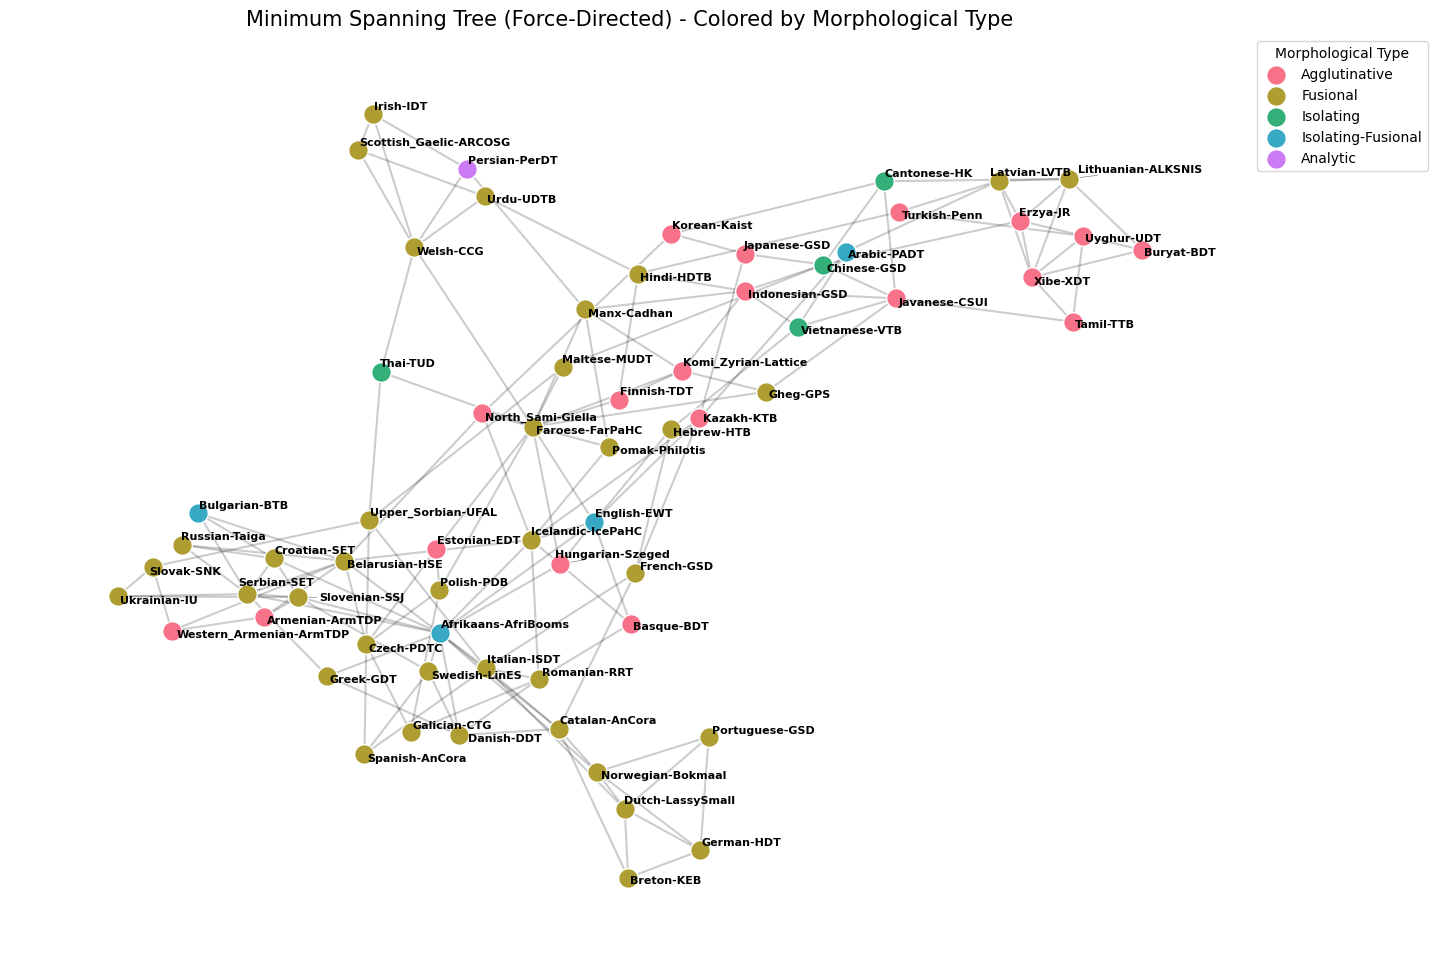

In [320]:
import networkx as nx
from scipy.sparse.csgraph import minimum_spanning_tree
from adjustText import adjust_text
from sklearn.neighbors import kneighbors_graph
# 1. Calculate the MST from your distance matrix
# mst_sparse = minimum_spanning_tree(dist_matrix)
# G = nx.from_scipy_sparse_array(mst_sparse)

# # 2. Relabel nodes to Language Names
# mapping = {i: lang for i, lang in enumerate(pos_df.index)}
# G = nx.relabel_nodes(G, mapping)

# # 3. Use a Force-Directed Layout (This fixes the overlapping branches)
# # k=... controls the optimal distance between nodes (increase it to spread them more)
# pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

knn_graph = kneighbors_graph(dist_matrix, n_neighbors=3, 
                             mode='connectivity', metric='precomputed')

G_knn = nx.from_scipy_sparse_array(knn_graph)
id_2_lang = {i: lang for i, lang in enumerate(pos_df.index)}
lang_2_id = {lang: i for i, lang in enumerate(pos_df.index)}
G_knn = nx.relabel_nodes(G_knn, id_2_lang)

# Now use the spring layout on THIS graph
for i, j in G_knn.edges():
    # Weight is inverse of distance (close things pull harder)
    G_knn[i][j]['weight'] = 1 / (dist_matrix[lang_2_id[i], lang_2_id[j]] + 0.1)

pos = nx.spring_layout(G_knn, weight='weight', k=0.5)
plt.figure(figsize=(16, 12))

# 4. Draw Edges
nx.draw_networkx_edges(G_knn, pos, alpha=0.2, edge_color='black', width=1.5)

# 5. Draw Nodes by Category (Family, Morphological type, etc.)
# Replace 'Group' with 'Morphological_Type' or 'Area' as needed
category = 'Morphological Type' 
unique_cats = styled_df[category].unique()
colors = sns.color_palette("husl", len(unique_cats))
cat_to_color = dict(zip(unique_cats, colors))

for cat in unique_cats:
    # Filter languages belonging to this category
    node_list = [n for n in G_knn.nodes() if styled_df.loc[n, category] == cat]
    
    nx.draw_networkx_nodes(
        G_knn, pos, 
        nodelist=node_list,
        node_color=[cat_to_color[cat]],
        label=cat,
        node_size=200,
        edgecolors='white',
        linewidths=1
    )

# 6. Smart Labels (to prevent them from overlapping too)
texts = []
for lang, (x, y) in pos.items():
    texts.append(plt.text(x, y, lang, fontsize=8, fontweight='bold'))

# This pushes the text labels away from each other and the nodes
adjust_text(texts, only_move={'points':'y', 'texts':'xy'}, arrowprops=dict(arrowstyle='->', color='gray', lw=0.5))

plt.title(f"Minimum Spanning Tree (Force-Directed) - Colored by {category}", fontsize=15)
plt.legend(scatterpoints=1, bbox_to_anchor=(1, 1), loc='upper left', title=category)
plt.axis('off') # Hide axes for a cleaner look
plt.show()

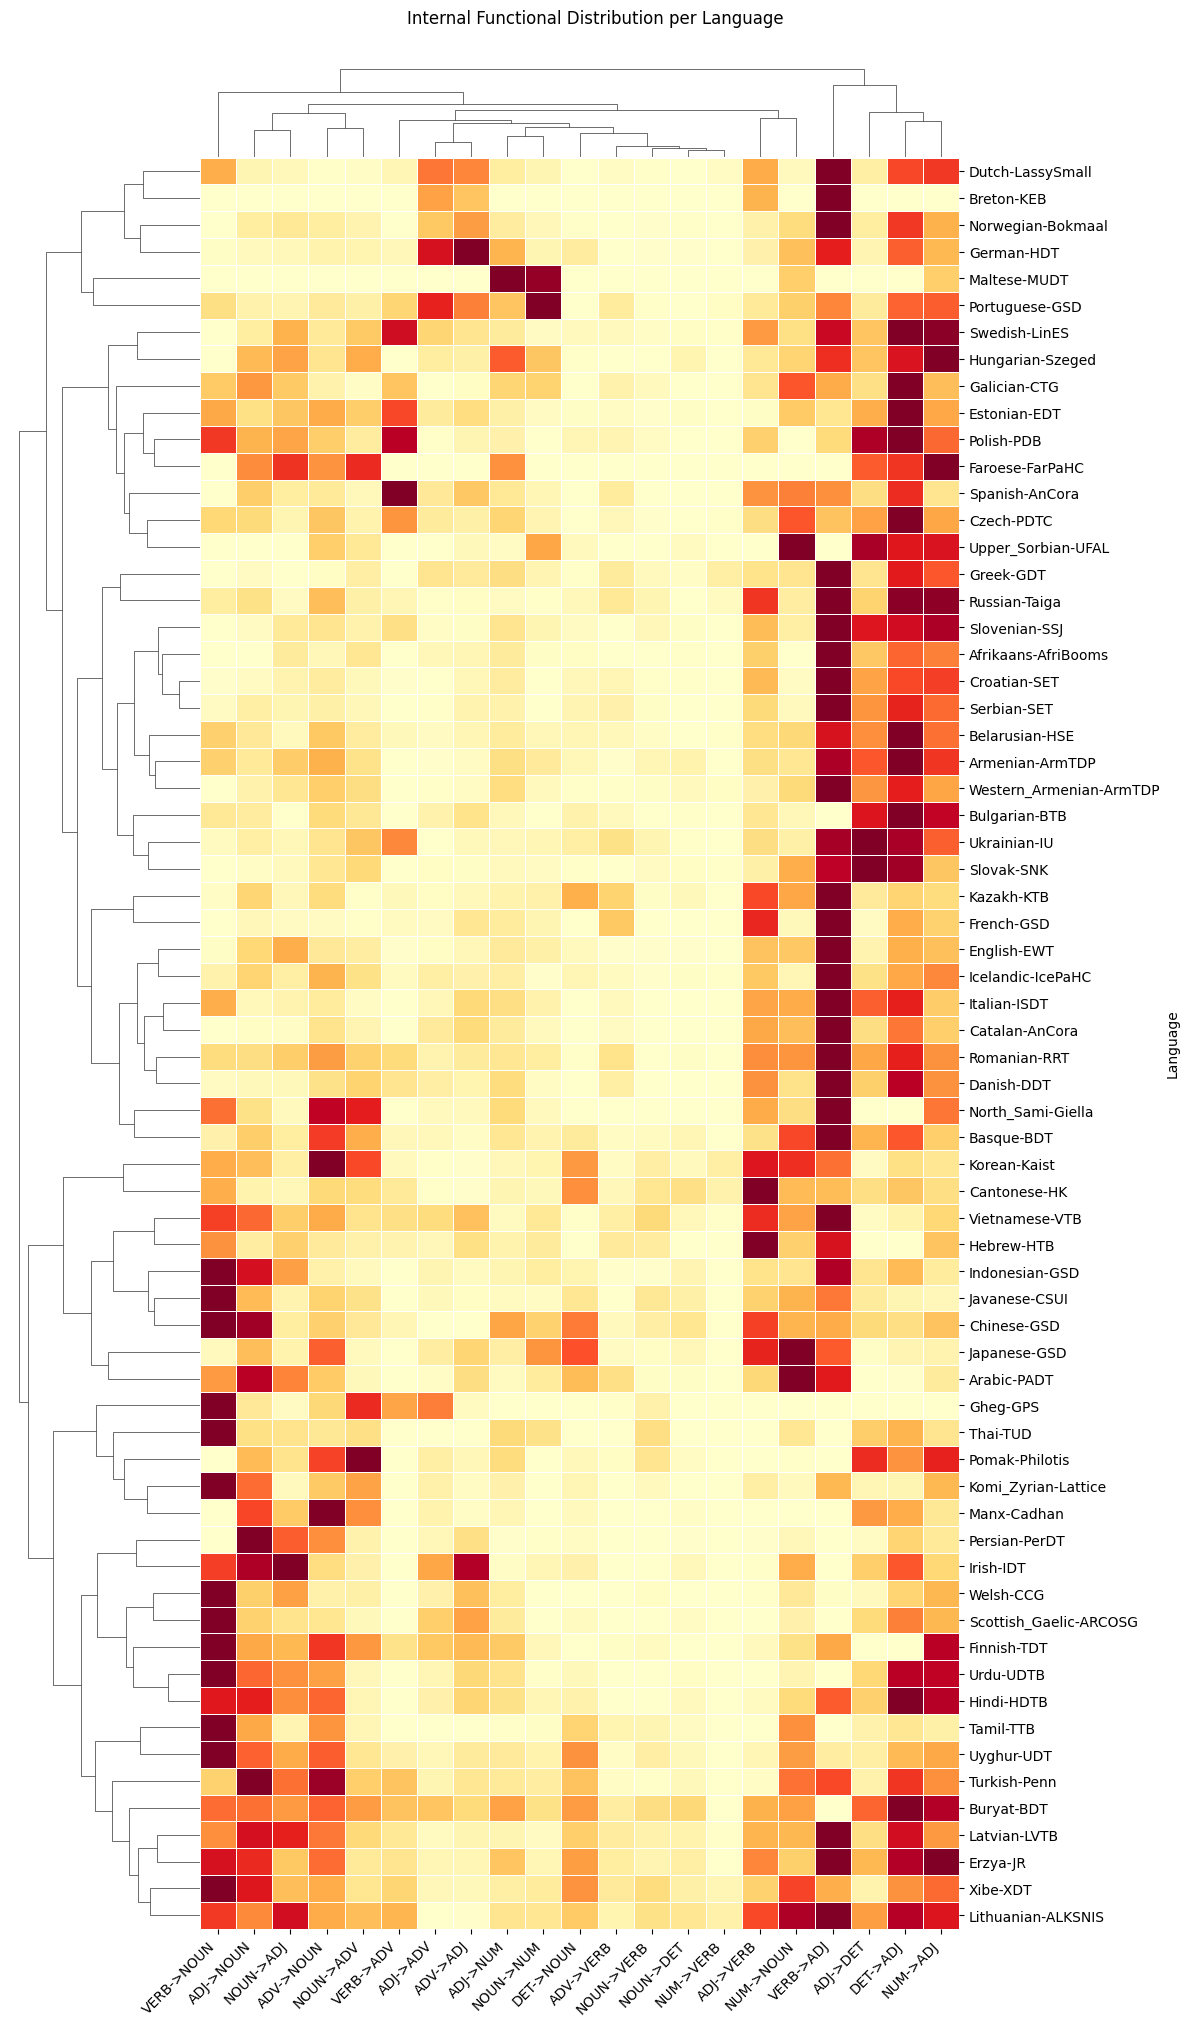

In [293]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import Normalizer
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

condensed_dist = squareform(dist_matrix, force='tovector')

# 2. Perform Linkage (Ward's method is usually best for clusters)
Z = linkage(condensed_dist, method='complete')

def plot_typological_heatmap(df, row_linkage=None, col_linkage=None):
    """
    df: The filtered_df containing the 6 languages and selected features.
    """
    # 1. Handle NaNs: To plot, we usually fill NaNs with 0 or a 'missing' color.
    # For a heatmap, 0 is often best to show the 'absence' of a feature.
    plot_data = df.fillna(0)
    plot_data = plot_data.drop('ADJ', axis=1)
    
    
    # 2. Normalize features (0 to 1 scale) so columns are comparable
    scaler = Normalizer(norm='max')
    # .T flips it so languages are columns, we scale, then flip back
    row_scaled_data = scaler.fit_transform(plot_data)
    
    normalized_df = pd.DataFrame(
        row_scaled_data, 
        columns=plot_data.columns, 
        index=plot_data.index
    )
    
    # 3. Create Heatmap
    g = sns.clustermap(
        data=normalized_df,
        method = "complete", 
        cmap='YlOrRd', 
        linewidths=.5, 
        figsize=(12, 20),
        # cbar_kws={'label': 'Relative Importance within Language'},
        row_linkage=row_linkage,
        col_linkage=col_linkage,
        row_cluster=True,
        cbar=False,
        dendrogram_ratio=(.2, .05)
    )
    g.ax_cbar.remove()
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, horizontalalignment='right')
    g.fig.suptitle('Internal Functional Distribution per Language', y=1.02)
    plt.show()

# Run the plot
plot_typological_heatmap(pos_df, row_linkage=Z)

In [300]:
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from scipy.spatial.distance import pdist

# 1. Convert the distance matrix to 'condensed' form for SciPy
# (Ensures the matrix is symmetric and zeros on the diagonal)
cos_distance_matrix = pdist(pos_df, metric='euclidean')
# condensed_dist = squareform(cos_distance_matrix, force='tovector')

# 2. Perform Linkage (Ward's method is usually best for clusters)
Z = linkage(cos_distance_matrix, method='average')

# 3. Plot the Dendrogram
plt.figure(figsize=(10, 10))
dendrogram(Z, labels=pos_df.index, leaf_rotation=0, orientation="right", distance_sort='ascending')
# plt.title("Hierarchical Typology of Languages")
plt.ylabel("Gower Distance")
plt.show()

ValueError: The condensed distance matrix must contain only finite values.

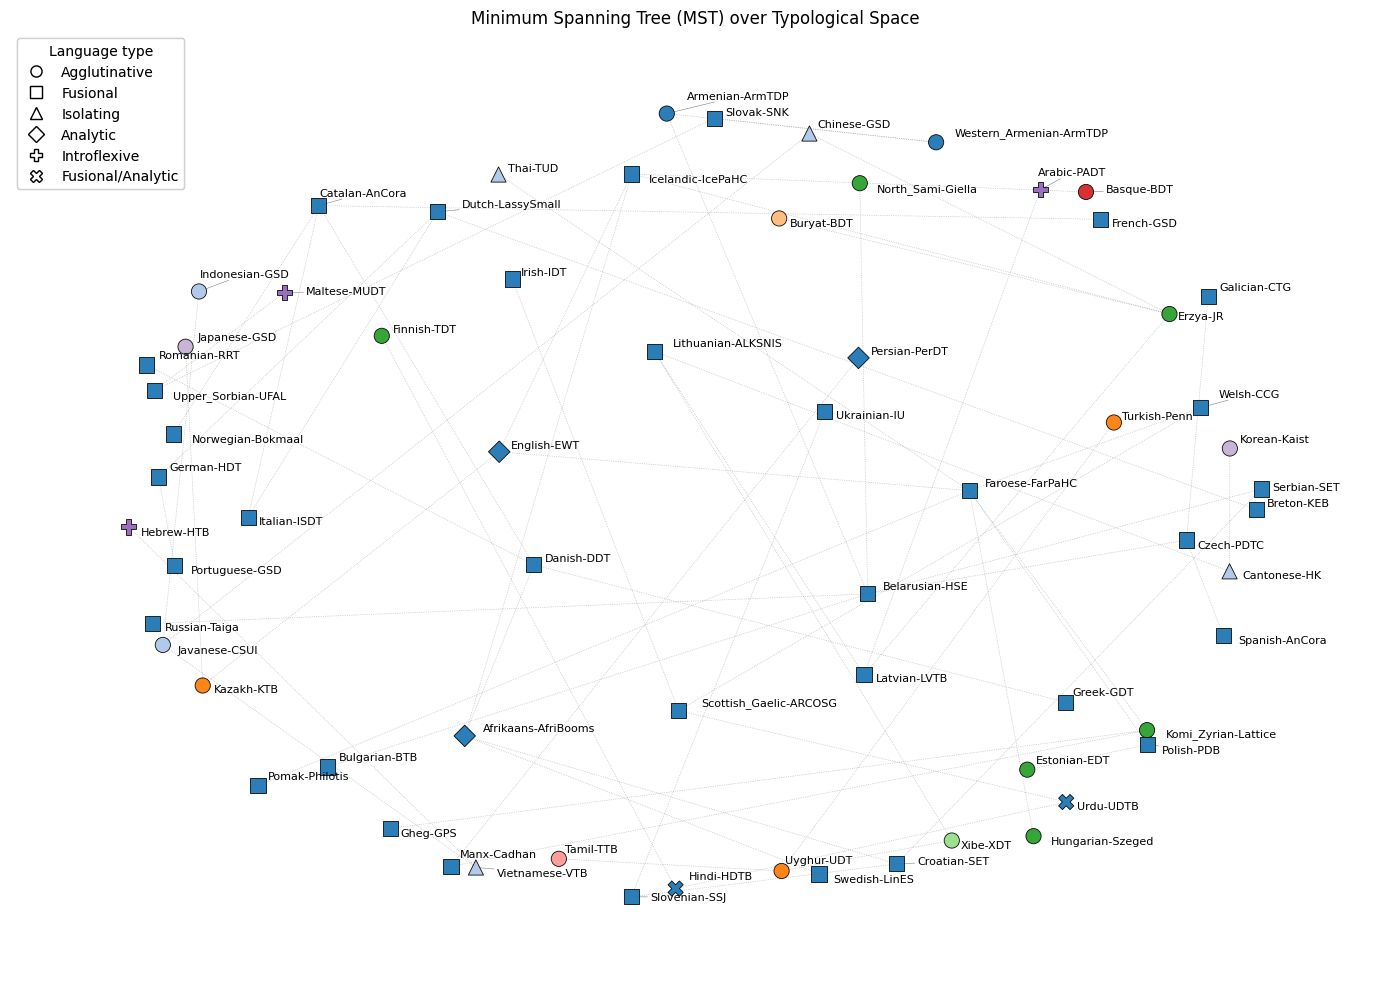

In [225]:
# ...existing code...
import networkx as nx
from scipy.sparse.csgraph import minimum_spanning_tree
from adjustText import adjust_text
import seaborn as sns

# 1. Compute the MST from your Gower distance matrix
mst_matrix = minimum_spanning_tree(dist_matrix).toarray()

# 2. Convert to a NetworkX graph for plotting (keep weights)
G = nx.from_numpy_array(mst_matrix)

# 3. Re-attach your language names as labels
mapping = {i: lang for i, lang in enumerate(pos_df.index)}
G = nx.relabel_nodes(G, mapping)

# 4. Choose columns for styling
group_col = "Group"                 # color by this (from styled_df)
type_col = "Morphological Type"     # marker by this (change if needed)

# 5. Build a layout that looks like a tree
pos = nx.spring_layout(G, seed=42, weight="weight", k=0.6)

# 6. Color map for groups
groups = styled_df[group_col] if group_col in styled_df.columns else pd.Series(index=styled_df.index, data="Unknown")
group_vals = [g for g in groups.unique() if pd.notna(g)]
palette = sns.color_palette("tab20", len(group_vals))
group_color_map = dict(zip(group_vals, palette))

# 7. Marker map for types
types = styled_df[type_col] if type_col in styled_df.columns else pd.Series(index=styled_df.index, data="Unknown")
type_vals = [t for t in types.unique() if pd.notna(t)]
marker_list = ['o', 's', '^', 'D', 'P', 'X', '*', 'v', '<', '>']
type_marker_map = {t: marker_list[i % len(marker_list)] for i, t in enumerate(type_vals)}

plt.figure(figsize=(14, 10))

# Draw edges with dotted style and weight-based widths
edges = G.edges(data=True)
edge_widths = [max(0.5, 2.5 * d.get("weight", 0.2)) for (_, _, d) in edges]
nx.draw_networkx_edges(
    G, pos,
    alpha=0.6,
    edge_color="gray",
    style="dotted",
    width=edge_widths
)

# Draw nodes by type (marker), colored by group
for t in type_vals:
    nodes_of_type = [n for n in G.nodes() if types.get(n, "Unknown") == t]
    node_colors = [group_color_map.get(groups.get(n, "Unknown"), "lightgray") for n in nodes_of_type]
    nx.draw_networkx_nodes(
        G, pos,
        nodelist=nodes_of_type,
        node_color=node_colors,
        node_size=120,
        edgecolors="black",
        linewidths=0.6,
        node_shape=type_marker_map.get(t, "o"),
        alpha=0.95
    )

# Add labels with collision avoidance
texts = []
for n, (x, y) in pos.items():
    texts.append(plt.text(x, y, n, fontsize=8))
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.4))

# Legends
from matplotlib.lines import Line2D
group_legend = [
    Line2D([0], [0], marker='o', color='w', label=g,
           markerfacecolor=group_color_map[g], markersize=8, markeredgecolor='black')
    for g in group_vals
]
type_legend = [
    Line2D([0], [0], marker=type_marker_map[t], color='w', label=t,
           markerfacecolor='white', markersize=8, markeredgecolor='black')
    for t in type_vals
]

plt.legend(handles=group_legend, title="Clusters (Group)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.gca().add_artist(plt.legend(handles=type_legend, title="Language type", loc="upper left"))

plt.title("Minimum Spanning Tree (MST) over Typological Space")
plt.axis("off")
plt.tight_layout()
plt.show()
# ...existing code...

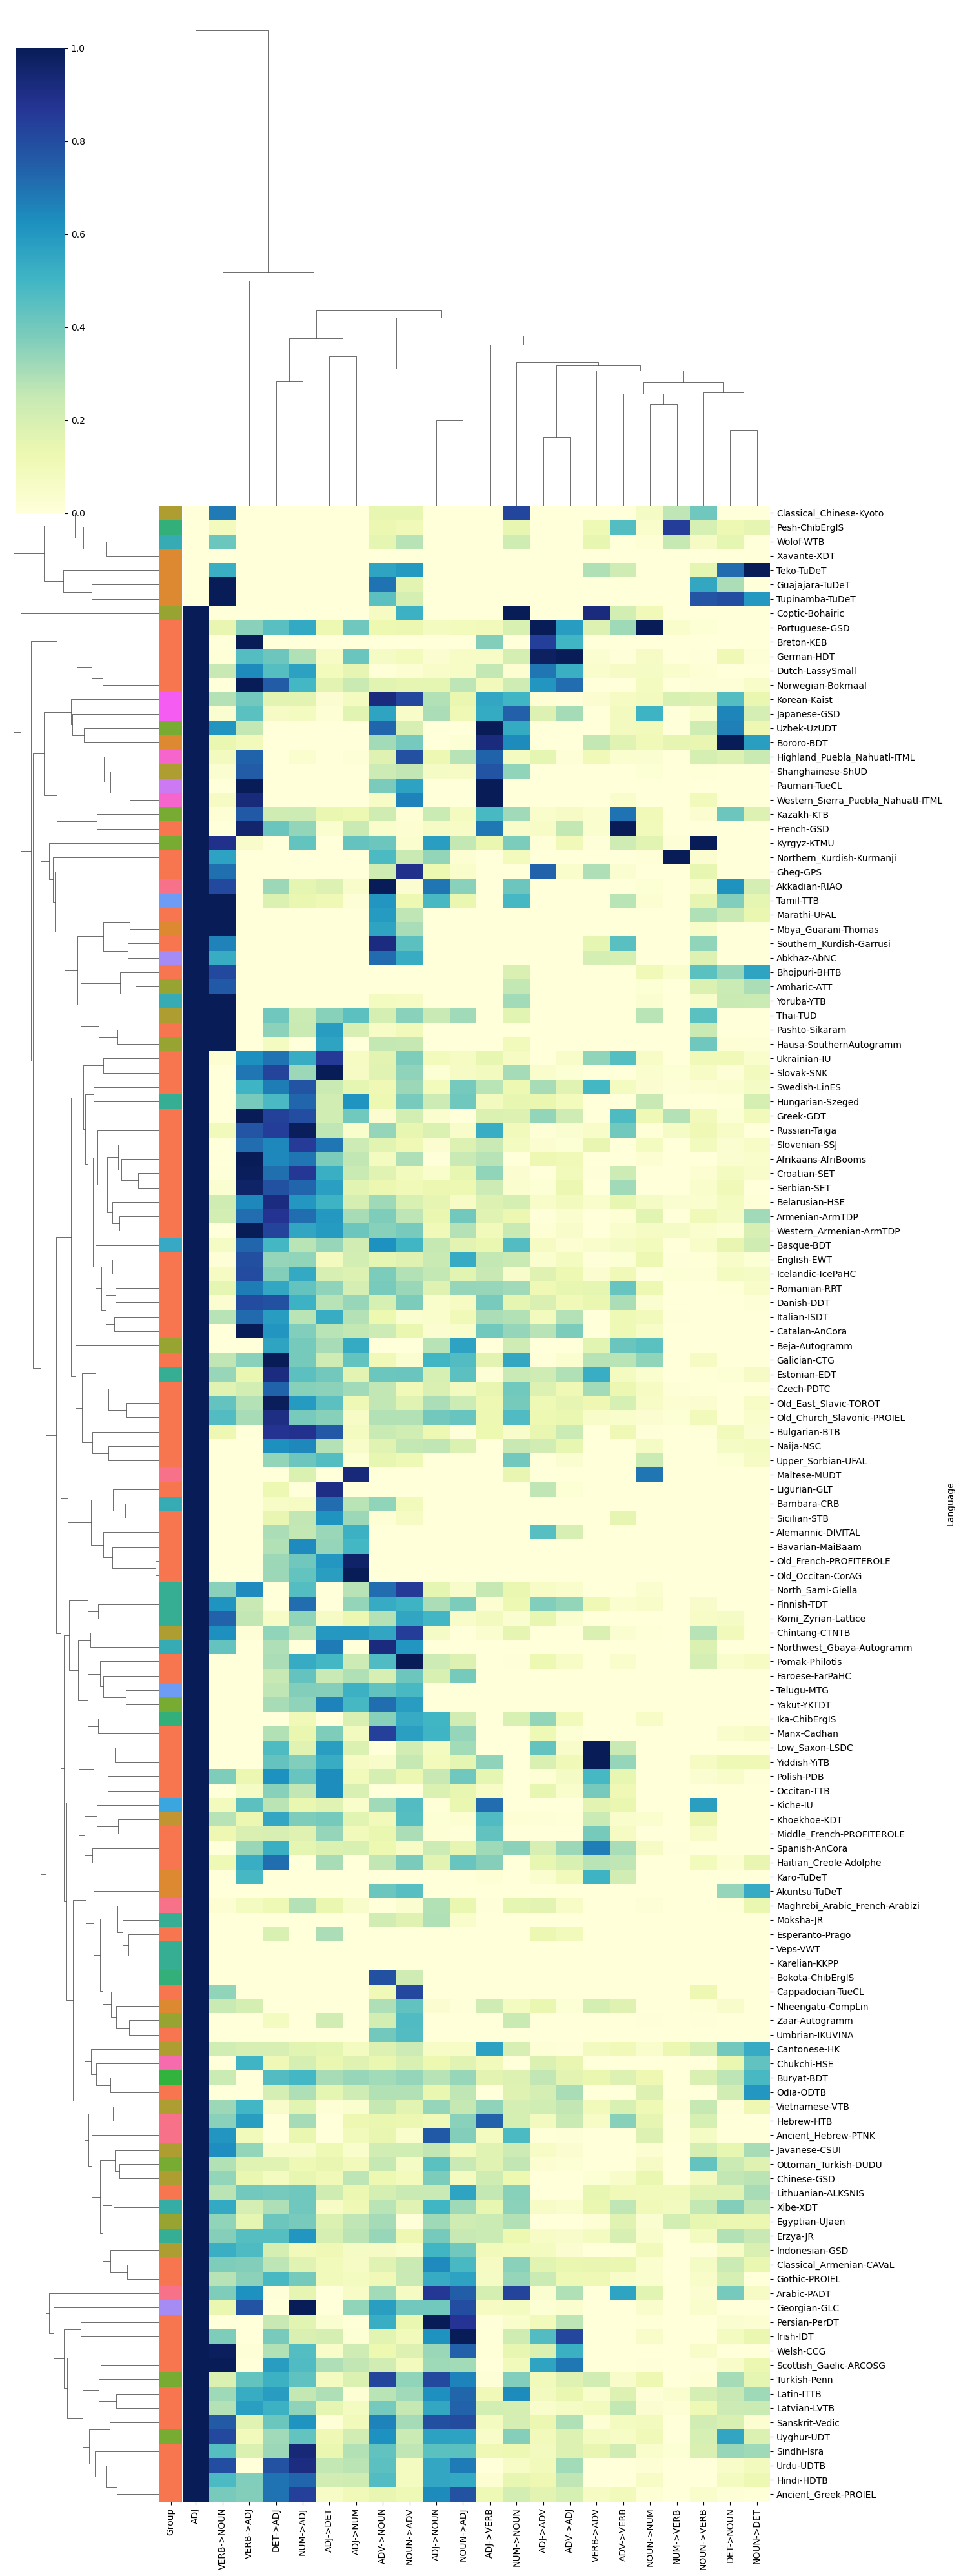

In [121]:
def plot_typological_heatmap(data_df, metadata_df, category='Area'):
    # Map the chosen category to colors for the sidebar
    unique_vals = metadata_df[category].unique()
    palette = sns.color_palette("husl", len(unique_vals))
    lut = dict(zip(unique_vals, palette))
    row_colors = metadata_df[category].map(lut)

    # Use seaborn's clustermap
    g = sns.clustermap(
        data_df.fillna(0), 
        row_colors=row_colors, 
        cmap="YlGnBu", 
        standard_scale=1, # Scales columns 0-1 to see patterns better
        figsize=(15, 40)
    )
    plt.show()

# Example:
plot_typological_heatmap(pos_df, styled_df, category='Group')

In [27]:
def select_features(master_matrix, main_category, variance_categories):
    selected_columns = []
    if main_category in master_matrix.columns:
        selected_columns.append(main_category)
    
    target_var = f"{main_category}_variance"
    if target_var in master_matrix.columns:
        selected_columns.append(target_var)
    
    for var_cat in variance_categories:
        
        var_col = f"{var_cat}_variance"
        if var_col in master_matrix.columns:
            selected_columns.append(var_col)
    
    relevant_poses = [main_category] + variance_categories

    for col in master_matrix.columns:
        if "->" in col:
            parts = col.split("->")
            if any(part in relevant_poses for part in parts):
                selected_columns.append(col)
    
    unique_cols = list(dict.fromkeys(selected_columns))

    # remove intj, x and sym because they are not really relevant for the typological classification and they add a lot of noise to the heatmap
    for col in unique_cols.copy():
        # Split the column name into its component parts (e.g., 'AUX_variance' -> ['AUX', 'variance'])
        parts = col.replace('->', '_').split('_')
        if any(pos in parts for pos in ["INTJ", "X", "SYM", "SCONJ", "CCONJ", "PROPN"]):
            unique_cols.remove(col)
    
    print(f"Selected columns for {main_category}: {unique_cols}")
    return master_matrix[unique_cols]

In [28]:
main_comparison_category = "ADJ"
variance_categories = ["NOUN", "VERB"]
pos_df = select_features(master_df, main_comparison_category, variance_categories)
pos_df = pos_df.dropna(thresh=10, subset=pos_df.columns[1:])
cat_features_mask = [col == main_comparison_category for col in pos_df.columns]
# pos_df = pos_df.loc[:, pos_df.nunique(dropna=True) > 1]
distance_matrix = manual_gower_matrix(pos_df, cat_cols=[main_comparison_category])

Selected columns for ADJ: ['ADJ', 'ADJ_variance', 'NOUN_variance', 'VERB_variance', 'ADJ->ADJ', 'ADJ->ADP', 'ADJ->ADV', 'ADJ->AUX', 'ADJ->DET', 'ADJ->NOUN', 'ADJ->NUM', 'ADJ->PART', 'ADJ->PRON', 'ADJ->VERB', 'ADP->ADJ', 'ADP->NOUN', 'ADP->VERB', 'ADV->ADJ', 'ADV->NOUN', 'ADV->VERB', 'AUX->ADJ', 'AUX->NOUN', 'AUX->VERB', 'DET->ADJ', 'DET->NOUN', 'DET->VERB', 'NOUN->ADJ', 'NOUN->ADP', 'NOUN->ADV', 'NOUN->AUX', 'NOUN->DET', 'NOUN->NOUN', 'NOUN->NUM', 'NOUN->PART', 'NOUN->PRON', 'NOUN->VERB', 'NUM->ADJ', 'NUM->NOUN', 'NUM->VERB', 'PART->ADJ', 'PART->NOUN', 'PART->VERB', 'PRON->ADJ', 'PRON->NOUN', 'PRON->VERB', 'VERB->ADJ', 'VERB->ADP', 'VERB->ADV', 'VERB->AUX', 'VERB->DET', 'VERB->NOUN', 'VERB->NUM', 'VERB->PART', 'VERB->PRON', 'VERB->VERB']


In [29]:
plot_data = pos_df.fillna(0)
    # drop columns with variance in the name
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('variance')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('ADP')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('AUX')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('PART')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('PRON')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('VERB->DET')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('VERB->NUM')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('DET->VERB')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('VERB->VERB')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('ADJ->ADJ')]
plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('NOUN->NOUN')]

In [30]:
plot_data

,ADJ,ADJ->ADV,ADJ->DET,ADJ->NOUN,ADJ->NUM,ADJ->VERB,ADV->ADJ,ADV->NOUN,ADV->VERB,DET->ADJ,...,NOUN->ADV,NOUN->DET,NOUN->NUM,NOUN->VERB,NUM->ADJ,NUM->NOUN,NUM->VERB,VERB->ADJ,VERB->ADV,VERB->NOUN
Language,,,,,,,,,,,,,,,,,,,,,
Akkadian-RIAO,1,0.000000,0.143506,0.575872,0.026045,0.000000,0.000000,0.779642,0.000000,0.290777,...,0.016160,0.044859,0.014600,0.025715,0.118089,0.413972,0.000000,0.000000,0.000000,0.810904
Armenian-ArmTDP,1,0.003645,0.476195,0.116146,0.165311,0.164241,0.022584,0.295049,0.004757,0.784768,...,0.150124,0.068233,0.112809,0.049694,0.537728,0.131029,0.000000,0.713168,0.000000,0.214686
Welsh-CCG,1,0.093642,0.043120,0.274908,0.123168,0.009789,0.326067,0.098965,0.000000,0.258473,...,0.102213,0.000000,0.000000,0.025297,0.350232,0.147054,0.000000,0.015446,0.000000,0.984554
Gheg-GPS,1,0.374418,0.000000,0.105569,0.000000,0.000000,0.026410,0.175699,0.009452,0.000000,...,0.499907,0.000000,0.000000,0.070620,0.000000,0.000000,0.000000,0.000000,0.293855,0.706145
Old_East_Slavic-TOROT,1,0.056577,0.353815,0.250324,0.059261,0.118503,0.094118,0.202579,0.059361,0.891723,...,0.093373,0.012112,0.038266,0.013528,0.447124,0.391661,0.010147,0.283770,0.117551,0.428079
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Hebrew-HTB,1,0.042768,0.000000,0.090908,0.063740,0.738369,0.150172,0.106074,0.106100,0.000000,...,0.073833,0.000000,0.103236,0.096222,0.235870,0.204231,0.001812,0.581185,0.061401,0.357414
Sicilian-STB,1,0.000000,0.490633,0.000000,0.176290,0.000000,0.000000,0.014747,0.044177,0.127813,...,0.041100,0.000000,0.000000,0.000000,0.196164,0.000000,0.000000,0.000000,0.000000,0.000000
Uyghur-UDT,1,0.048172,0.090835,0.478779,0.117731,0.053752,0.113306,0.486844,0.018258,0.285839,...,0.131391,0.039620,0.071340,0.096457,0.328543,0.366161,0.000000,0.099707,0.077943,0.815930


In [31]:
df_main = plot_data
df_groups = pd.read_csv('/Users/madalina/Downloads/Typometrics configuration - language to group.csv')
df_markers = pd.read_csv('/Users/madalina/Downloads/Typometrics configuration - appearance.csv')

In [32]:
df_main['Language_Key'] = df_main.index.str.split('-').str[0].str.replace('_', '')
df = df_main.merge(df_groups, left_on='Language_Key', right_on='Language', suffixes=('', '_info'))
df = df.merge(df_markers, on='Group', how='left')


In [33]:
df

,ADJ,ADJ->ADV,ADJ->DET,ADJ->NOUN,ADJ->NUM,ADJ->VERB,ADV->ADJ,ADV->NOUN,ADV->VERB,DET->ADJ,...,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Default Color,Default Marker,Unnamed: 3,options are:,markers,colors
0,1,0.000000,0.143506,0.575872,0.026045,0.000000,0.000000,0.779642,0.000000,0.290777,...,NaN,NaN,NaN,NaN,orange,crossRot,NaN,NaN,rectRot,NaN
1,1,0.003645,0.476195,0.116146,0.165311,0.164241,0.022584,0.295049,0.004757,0.784768,...,NaN,NaN,NaN,NaN,royalBlue,triangle,NaN,NaN,dash,NaN
2,1,0.093642,0.043120,0.274908,0.123168,0.009789,0.326067,0.098965,0.000000,0.258473,...,NaN,NaN,NaN,NaN,royalBlue,triangle,NaN,NaN,dash,NaN
3,1,0.374418,0.000000,0.105569,0.000000,0.000000,0.026410,0.175699,0.009452,0.000000,...,NaN,NaN,NaN,NaN,royalBlue,triangle,NaN,NaN,dash,NaN
4,1,0.056577,0.353815,0.250324,0.059261,0.118503,0.094118,0.202579,0.059361,0.891723,...,NaN,NaN,NaN,NaN,royalBlue,triangle,NaN,NaN,dash,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,1,0.506752,0.096350,0.062979,0.219334,0.100669,0.364766,0.099176,0.094415,0.405795,...,NaN,NaN,NaN,NaN,royalBlue,triangle,NaN,NaN,dash,NaN
115,1,0.017022,0.001017,0.724846,0.030649,0.205600,0.180804,0.244344,0.165559,0.005721,...,NaN,NaN,NaN,NaN,orange,crossRot,NaN,NaN,rectRot,NaN
116,1,0.042768,0.000000,0.090908,0.063740,0.738369,0.150172,0.106074,0.106100,0.000000,...,NaN,NaN,NaN,NaN,orange,crossRot,NaN,NaN,rectRot,NaN
117,1,0.000000,0.490633,0.000000,0.176290,0.000000,0.000000,0.014747,0.044177,0.127813,...,Sicilian,NaN,NaN,NaN,royalBlue,triangle,NaN,NaN,dash,NaN


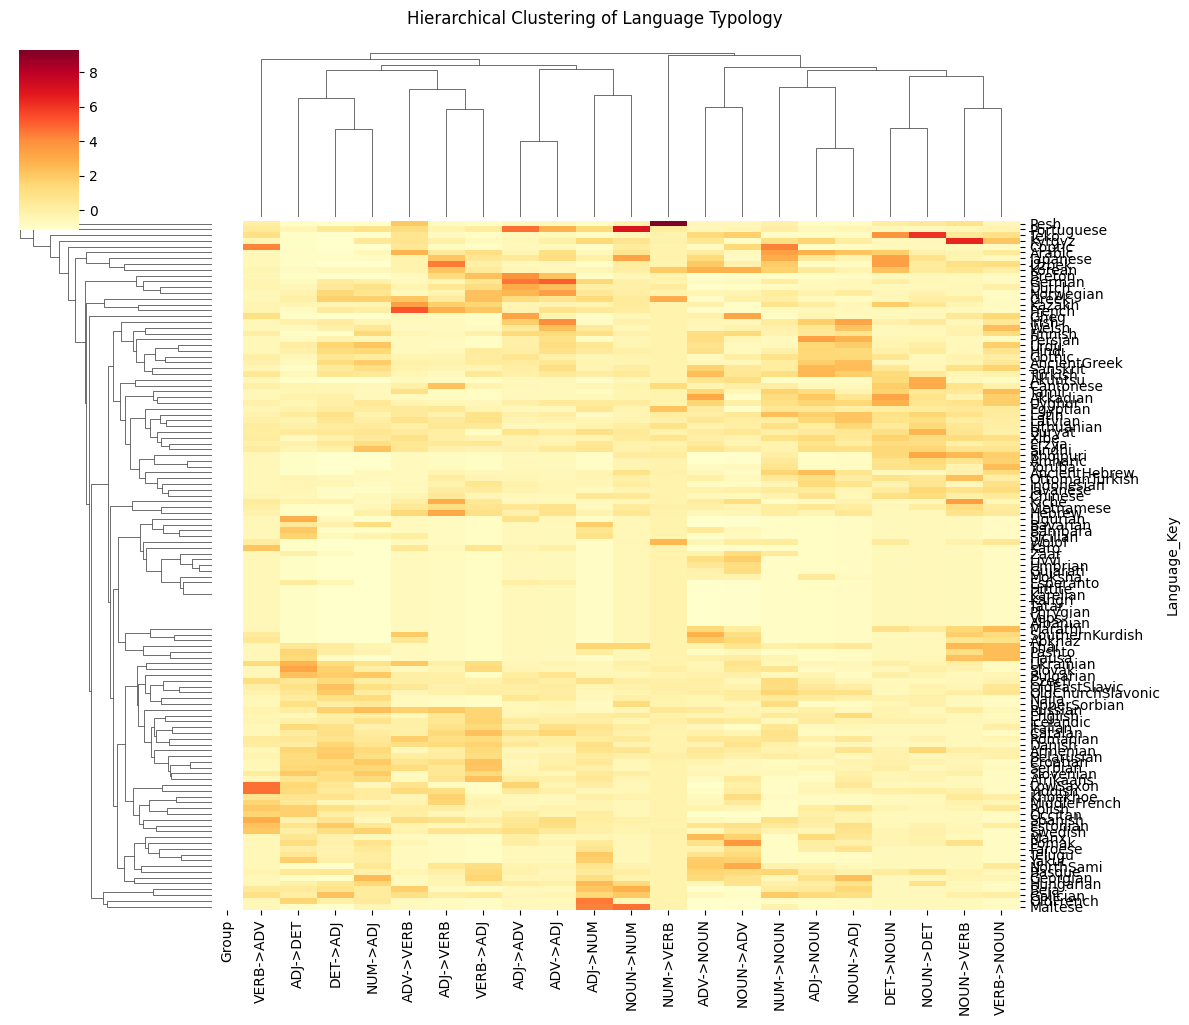

In [38]:
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

features = [c for c in df_main.columns if '->' in c]
X = df[features].fillna(0)
X_scaled = StandardScaler().fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=df['Language_Key'])

X_scaled = StandardScaler().fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=df['Language_Key'])

# --- REPRESENTATION 1: CLUSTERED HEATMAP ---
# Create a sidebar color mapping for groups
group_colors = dict(zip(df_markers['Group'], df_markers['Default Color']))
row_colors = df['Group'].map(group_colors)

g = sns.clustermap(X_scaled_df, 
                   cmap="YlOrRd",
                   row_colors=row_colors, 
                   figsize=(12, 10),
                   yticklabels=True)
g.fig.suptitle("Hierarchical Clustering of Language Typology", y=1.02)
plt.show()

In [48]:
from sklearn.decomposition import PCA
from sklearn.manifold import MDS

# pca = PCA(n_components=2)
# coords = pca.fit_transform(X_scaled)

mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
# 2. Fit and transform the Gower distance matrix
coords = mds.fit_transform(distance_matrix)

df = df.reset_index(drop=True)  # Reset index to avoid issues
df['PC1'], df['PC2'] = coords[:, 0], coords[:, 1]

plt.figure(figsize=(10, 8))
for group in df['Group'].unique():
    subset = df[df['Group'] == group].copy()
    if len(subset) == 0:
        continue
    
    raw_color = subset['Default Color'].iloc[0]
    # If raw_color is NaN (which is a float), use 'grey' as a fallback
    current_color = raw_color if pd.notna(raw_color) else 'grey'
    symbol_name = subset['Default Marker'].iloc[0]
    # Map 'triangle' to matplotlib '^', etc.
    m_map = {'triangle': '^', 'star': '*', 'rect': 's', 'cross': "+", 'circle': 'o', 'crossRot': 'X'}
    marker = m_map.get(symbol_name, 'o')
    
    plt.scatter(subset['PC1'].tolist(), subset['PC2'].tolist(), 
                label=group, 
                color=current_color, 
                marker=marker, s=150, edgecolors='black', alpha=0.7)

# Add labels to points
for idx, row in df.iterrows():
    plt.annotate(row['Language_Key'], (row['PC1'], row['PC2']), size=8)

plt.title("Typological Space of Adjective Transitions")
# plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
# plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ValueError: Length of values (146) does not match length of index (119)

In [37]:
X_scaled_df

,ADJ->ADV,ADJ->DET,ADJ->NOUN,ADJ->NUM,ADJ->VERB,ADV->ADJ,ADV->NOUN,ADV->VERB,DET->ADJ,DET->NOUN,...,NOUN->ADV,NOUN->DET,NOUN->NUM,NOUN->VERB,NUM->ADJ,NUM->NOUN,NUM->VERB,VERB->ADJ,VERB->ADV,VERB->NOUN
Language_Key,,,,,,,,,,,,,,,,,,,,,
Akkadian,-0.576822,-0.189612,2.066504,-0.648437,-0.751712,-0.647998,3.132165,-0.704151,-0.012849,3.180791,...,-0.928818,0.799400,-0.376000,-0.243226,-0.583927,1.238575,-0.243794,-0.863046,-0.518993,1.823579
Armenian,-0.539181,1.566805,-0.276598,0.791203,0.105970,-0.440783,0.497249,-0.607455,1.848101,-0.205232,...,0.216819,1.528980,0.689788,0.109661,1.416253,-0.229997,-0.243794,1.351521,-0.518993,-0.124784
Welsh,0.390084,-0.719592,0.532572,0.355558,-0.700593,2.343818,-0.568939,-0.704151,-0.134546,-0.630353,...,-0.192910,-0.600782,-0.534447,-0.249372,0.522565,-0.146821,-0.243794,-0.815081,-0.518993,2.391043
Gheg,3.289239,-0.947244,-0.330504,-0.917668,-0.751712,-0.405674,-0.151703,-0.512015,-1.108258,-0.630353,...,3.208110,-0.600782,-0.534447,0.417608,-1.146791,-0.910081,-0.243794,-0.863046,1.001794,1.481242
OldEastSlavic,0.007362,0.920708,0.407273,-0.305070,-0.132879,0.215580,-0.005549,0.502456,2.251019,-0.608495,...,-0.268507,-0.222737,-0.119176,-0.422571,0.984396,1.122777,0.036249,0.018130,0.089368,0.572557
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Portuguese,4.655656,-0.438566,-0.547573,1.349657,-0.226011,2.698898,-0.567789,1.214979,0.420444,-0.630353,...,-0.448644,-0.600782,6.988781,-0.482945,0.816591,0.098221,0.208819,0.244237,0.395273,-0.355167
Arabic,-0.401059,-0.941873,2.825784,-0.600839,0.321949,1.010959,0.221547,2.661108,-1.086708,1.820744,...,-0.717884,-0.163188,0.691712,-0.406552,-0.601253,3.386820,-0.243794,1.076257,-0.518993,0.400659
Hebrew,-0.135218,-0.947244,-0.405229,-0.258772,3.104110,0.729904,-0.530283,1.452502,-1.108258,-0.630353,...,-0.435609,-0.600782,0.585901,0.794382,-0.022535,0.149949,-0.193794,0.941680,-0.201223,0.341632
